# Phân tích dataset cuối
Notebook thống kê quy mô, chất lượng, phân phối nhãn, độ dài văn bản và các annotation hallucination. Mỗi phần có ghi chú cách đọc kết quả; các kết luận định lượng được sinh từ dữ liệu khi chạy **Run All**.

Đơn vị phân tích: **mẫu QA**, **tài liệu/chunk** và **span annotation**. Số từ ở đây là số đơn vị tách bằng khoảng trắng, không phải số token của mô hình hoặc từ đã phân đoạn tiếng Việt. Notebook chỉ phân tích, không thay đổi dữ liệu gốc.

## Kết quả đã kiểm tra trên dataset hiện tại

# Tổng kết dataset cuối
- Số QA: 17,082; tài liệu: 7,822; chunk: 10,346.
- Tỷ lệ mẫu có hallucination: 48.11%.
- Nhãn lớn nhất/nhỏ nhất: no_hallucination / mixed_hallucination; tỷ số 6.60.
- Tổng span: 9,739; QA có span: 8,218.
- Cảnh báo annotation: 0 trên 0 QA; cần rà soát thủ công.
- Dòng trùng hoàn toàn sau lần đầu: 0.
- Nhóm content chia sẻ giữa nhiều tài liệu: 0.
- Trung vị độ dài content/question/answer: 89/21/27 đơn vị tách khoảng trắng.

Các cảnh báo không tự động có nghĩa là dữ liệu sai. Chưa đánh giá chất lượng evidence về ngữ nghĩa, hiệu quả làm sạch trước/sau hoặc rò rỉ giữa các tập đã chia.


Kết quả được kiểm tra lại ngày 11/10/2026. Nếu đổi dataset, chạy lại notebook để cập nhật thống kê.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path("output/data_final.json"), Path("dataset_curation/output/data_final.json")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Không tìm thấy output/data_final.json. Chạy từ thư mục src hoặc dataset_curation.")
df = pd.read_json(DATA_PATH).reset_index(drop=True)
assert len(df), "Dataset rỗng"
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": False, "font.size": 10})
pd.set_option("display.max_columns", 30)
REPORT_DIR = DATA_PATH.parent / "analysis_final"
REPORT_DIR.mkdir(exist_ok=True)

def note(text):
    display(Markdown(text))

def save_table(table, name):
    table.to_csv(REPORT_DIR / f"{name}.csv", index=True, encoding="utf-8-sig")

def finish(name):
    plt.tight_layout()
    plt.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

def distribution(series, title, name):
    counts = series.fillna("<missing>").value_counts()
    table = counts.rename("count").to_frame()
    table["percent"] = (counts / len(series) * 100).round(2) if len(series) else 0
    display(table)
    save_table(table, name)
    if len(counts):
        ax = counts.sort_values().plot.barh(title=title, color="#4472C4")
        ax.set_xlabel("Số lượng")
        for i, v in enumerate(counts.sort_values()):
            ax.text(v, i, f" {v:,}", va="center")
        finish(name)
    return table

display(df.head())
df.info()


,qa_id,chunk_id,doc_id,domain,content,question,answer,label,question_type,span_label
0,finance_sbv_50100_chunk7__qa2,finance_sbv_50100_chunk7,finance_sbv_50100,finance,Qua thực tiễn triển khai quy định về thanh toá...,Tại sao cần phải hướng dẫn chi tiết các nội du...,Cần hướng dẫn chi tiết vì các quy định hiện hà...,no_hallucination,answerable,[]
1,education_hueuni_64954_chunk7__qa3,education_hueuni_64954_chunk7,education_hueuni_64954,education,"Khởi nghiệp phải đi đôi với đổi mới sáng tạo, ...",Khởi nghiệp gắn liền với những yếu tố cốt lõi ...,Khởi nghiệp gắn liền với đổi mới sáng tạo và s...,mixed_hallucination,answerable,"[{'span': 'đi vào hình thức', 'label': 'contra..."
2,news_thanhnien_54045_chunk7__qa1,news_thanhnien_54045_chunk7,news_thanhnien_54045,news,"Góp ý dự thảo luật, ông Sỹ Hồng Nam, Phó chánh...",Ông Sỹ Hồng Nam đề nghị mở rộng khái niệm ngườ...,Ông Sỹ Hồng Nam đề nghị mở rộng khái niệm ngườ...,intrinsic_hallucination,answerable,"[{'span': 'doanh nghiệp nhà nước', 'label': 'c..."
3,news_tuoitre_49858_chunk4__qa3,news_tuoitre_49858_chunk4,news_tuoitre_49858,news,"Không chỉ Keno, thời gian gần đây xổ số quay n...",Thời gian diễn ra các kỳ quay số của giải Lott...,Các kỳ quay số Lotto 5/35 diễn ra vào 13 giờ v...,no_hallucination,answerable,[]
4,legal_congbao_48849_chunk324__qa2,legal_congbao_48849_chunk324,legal_congbao_48849,legal,2. Đối với công trình có ảnh hưởng lớn đến an ...,"Chủ sở hữu hoặc người quản lý, sử dụng công tr...","Chủ sở hữu hoặc người quản lý, sử dụng công tr...",extrinsic_hallucination,answerable,"[{'span': 'bằng văn bản', 'label': 'unsupporte..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17082 entries, 0 to 17081
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qa_id          17082 non-null  object
 1   chunk_id       17082 non-null  object
 2   doc_id         17082 non-null  object
 3   domain         17082 non-null  object
 4   content        17082 non-null  object
 5   question       17082 non-null  object
 6   answer         17082 non-null  object
 7   label          17082 non-null  object
 8   question_type  17082 non-null  object
 9   span_label     17082 non-null  object
dtypes: object(10)
memory usage: 1.3+ MB


## 1. Quy mô và chất lượng dữ liệu
Kiểm tra dữ liệu thiếu, chuỗi rỗng, kiểu dữ liệu và ID trùng. Danh sách `span_label=[]` là hợp lệ với mẫu không hallucination, nên không được coi là dữ liệu thiếu. Evidence rỗng ở span unsupported cũng cần được đọc theo ý nghĩa annotation.

In [2]:
overview = pd.Series({"qa_rows": len(df), "columns": df.shape[1],
    "unique_qa_id": df.qa_id.nunique(), "unique_documents": df.doc_id.nunique(),
    "unique_chunks": df.chunk_id.nunique(), "domains": df.domain.nunique()}, name="value").to_frame()
display(overview)
save_table(overview, "overview")
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
    "blank_string": df.apply(lambda c: c.map(lambda v: isinstance(v, str) and not v.strip()).sum()),
    "python_types": df.apply(lambda c: ", ".join(sorted(c.map(lambda v: type(v).__name__).unique())))})
quality["missing_or_blank_percent"] = ((quality.missing + quality.blank_string) / len(df) * 100).round(2)
display(quality)
save_table(quality, "column_quality")
canonical = df.apply(lambda c: c.map(lambda v: json.dumps(v, ensure_ascii=False, sort_keys=True)))
duplicate_stats = pd.Series({"extra_exact_rows": canonical.duplicated().sum(),
    "extra_qa_ids": df.duplicated("qa_id").sum(),
    "extra_content_question_answer": df.duplicated(["content", "question", "answer"]).sum(),
    "extra_content_question": df.duplicated(["content", "question"]).sum()}, name="count").to_frame()
display(duplicate_stats)
save_table(duplicate_stats, "duplicates")
note(f"**Nhận xét:** Có **{len(df):,} mẫu**, từ **{df.doc_id.nunique():,} tài liệu** và **{df.chunk_id.nunique():,} chunk. Tổng ô thiếu hoặc chuỗi rỗng là **{int((quality.missing + quality.blank_string).sum()):,}**. Có **{int(duplicate_stats.loc['extra_exact_rows', 'count']):,} dòng trùng toàn bộ** sau lần xuất hiện đầu tiên. Trùng content–question có thể là các biến thể câu trả lời được tạo có chủ đích; cần xem theo nhóm trước khi loại bỏ.")
display(df[df.duplicated("qa_id", keep=False)].head(10))


,value
qa_rows,17082
columns,10
unique_qa_id,17082
unique_documents,7822
unique_chunks,10346
domains,6


,dtype,missing,blank_string,python_types,missing_or_blank_percent
qa_id,object,0,0,str,0.0
chunk_id,object,0,0,str,0.0
doc_id,object,0,0,str,0.0
domain,object,0,0,str,0.0
content,object,0,0,str,0.0
question,object,0,0,str,0.0
answer,object,0,0,str,0.0
label,object,0,0,str,0.0
question_type,object,0,0,str,0.0
span_label,object,0,0,list,0.0


,count
extra_exact_rows,0
extra_qa_ids,0
extra_content_question_answer,0
extra_content_question,0


**Nhận xét:** Có **17,082 mẫu**, từ **7,822 tài liệu** và **10,346 chunk. Tổng ô thiếu hoặc chuỗi rỗng là **0**. Có **0 dòng trùng toàn bộ** sau lần xuất hiện đầu tiên. Trùng content–question có thể là các biến thể câu trả lời được tạo có chủ đích; cần xem theo nhóm trước khi loại bỏ.

,qa_id,chunk_id,doc_id,domain,content,question,answer,label,question_type,span_label


## 2. Phân phối nhãn, lĩnh vực và loại câu hỏi
Số lượng và tỷ lệ cho biết dataset nghiêng về nhóm nào. So sánh theo hàng trong bảng chéo để đánh giá tỷ lệ hallucination bên trong từng lĩnh vực/loại câu hỏi. Đây là mô tả dữ liệu, chưa chứng minh nguyên nhân hoặc chất lượng mô hình.

,count,percent
label,,
no_hallucination,8864,51.89
intrinsic_hallucination,3665,21.46
extrinsic_hallucination,3210,18.79
mixed_hallucination,1343,7.86


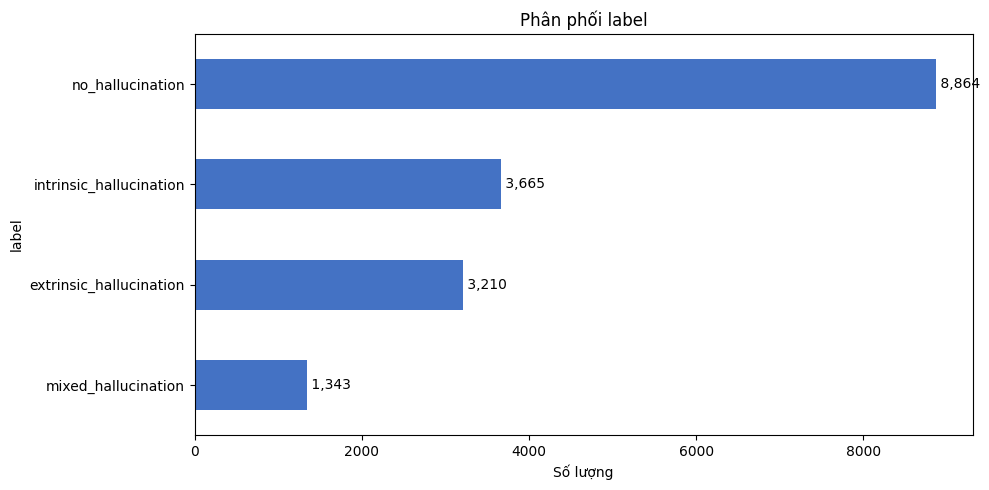

,count,percent
domain,,
news,3385,19.82
science,3035,17.77
finance,2913,17.05
medical,2731,15.99
legal,2529,14.81
education,2489,14.57


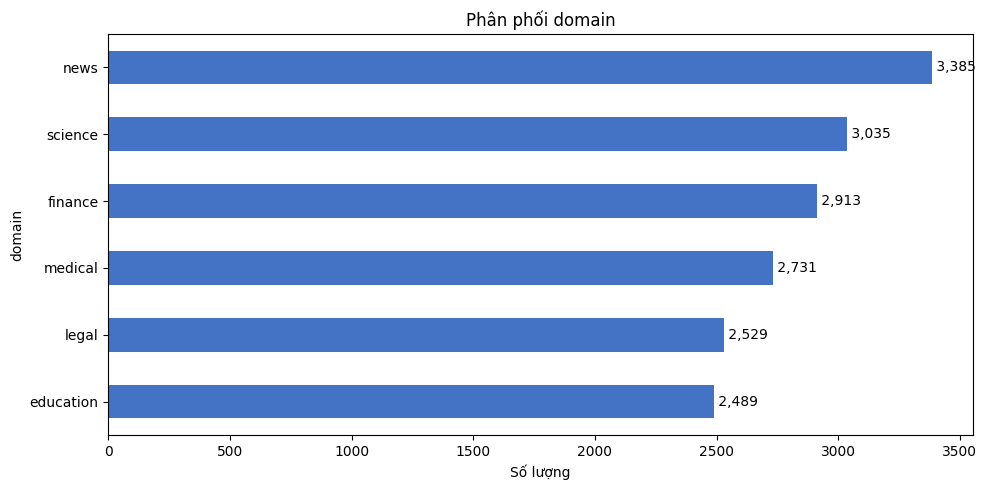

,count,percent
question_type,,
answerable,14879,87.10
unanswerable,1644,9.62
false_premise,559,3.27


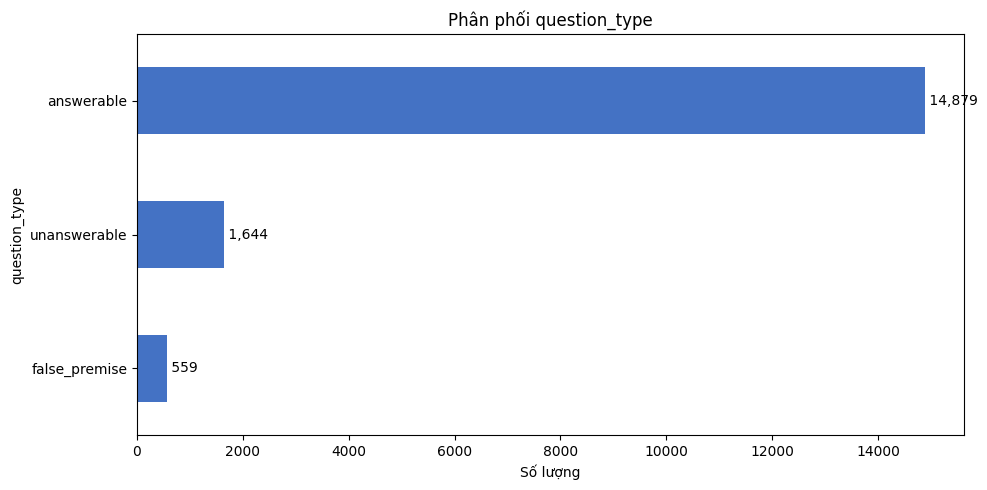

**Nhận xét:** Nhãn nhiều nhất là **no_hallucination** (8,864 mẫu, 51.89%); nhãn ít nhất là **mixed_hallucination** (1,343 mẫu). Tỷ số lớn nhất/nhỏ nhất là **6.60**. Tỷ lệ mẫu có hallucination là **48.11%**. Khi đánh giá mô hình, nên báo cáo kết quả từng nhãn và macro-F1 để quan sát ảnh hưởng của mất cân bằng.

**domain × label:** bảng số lượng và tỷ lệ % theo hàng.

label,extrinsic_hallucination,intrinsic_hallucination,mixed_hallucination,no_hallucination
domain,,,,
education,464,497,195,1333
finance,487,638,249,1539
legal,482,578,189,1280
medical,608,550,187,1386
news,662,753,273,1697
science,507,649,250,1629


label,extrinsic_hallucination,intrinsic_hallucination,mixed_hallucination,no_hallucination
domain,,,,
education,18.64,19.97,7.83,53.56
finance,16.72,21.90,8.55,52.83
legal,19.06,22.85,7.47,50.61
medical,22.26,20.14,6.85,50.75
news,19.56,22.25,8.06,50.13
science,16.71,21.38,8.24,53.67


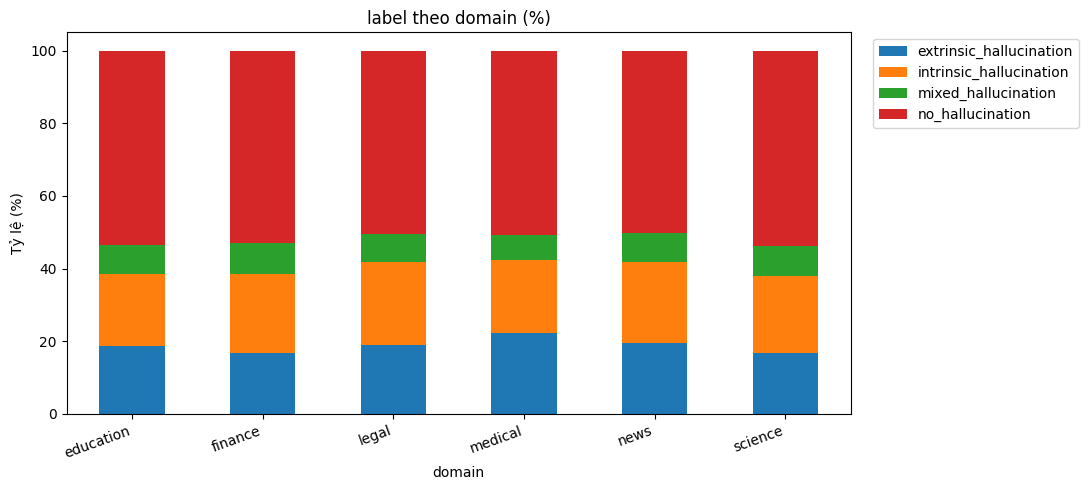

**question_type × label:** bảng số lượng và tỷ lệ % theo hàng.

label,extrinsic_hallucination,intrinsic_hallucination,mixed_hallucination,no_hallucination
question_type,,,,
answerable,2483,3558,1213,7625
false_premise,104,81,88,286
unanswerable,623,26,42,953


label,extrinsic_hallucination,intrinsic_hallucination,mixed_hallucination,no_hallucination
question_type,,,,
answerable,16.69,23.91,8.15,51.25
false_premise,18.60,14.49,15.74,51.16
unanswerable,37.90,1.58,2.55,57.97


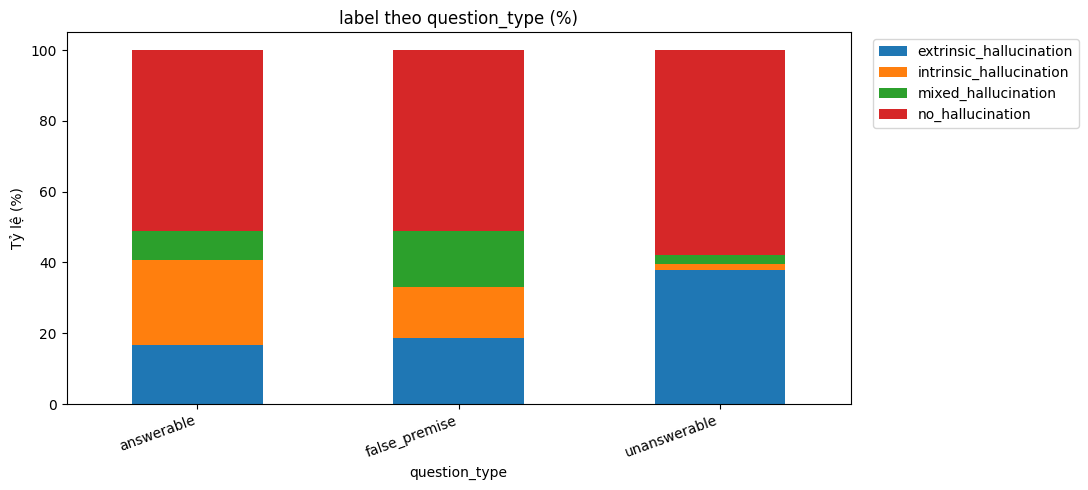

**domain × question_type:** bảng số lượng và tỷ lệ % theo hàng.

question_type,answerable,false_premise,unanswerable
domain,,,
education,2144,70,275
finance,2502,131,280
legal,2279,69,181
medical,2392,76,263
news,2937,131,317
science,2625,82,328


question_type,answerable,false_premise,unanswerable
domain,,,
education,86.14,2.81,11.05
finance,85.89,4.50,9.61
legal,90.11,2.73,7.16
medical,87.59,2.78,9.63
news,86.77,3.87,9.36
science,86.49,2.70,10.81


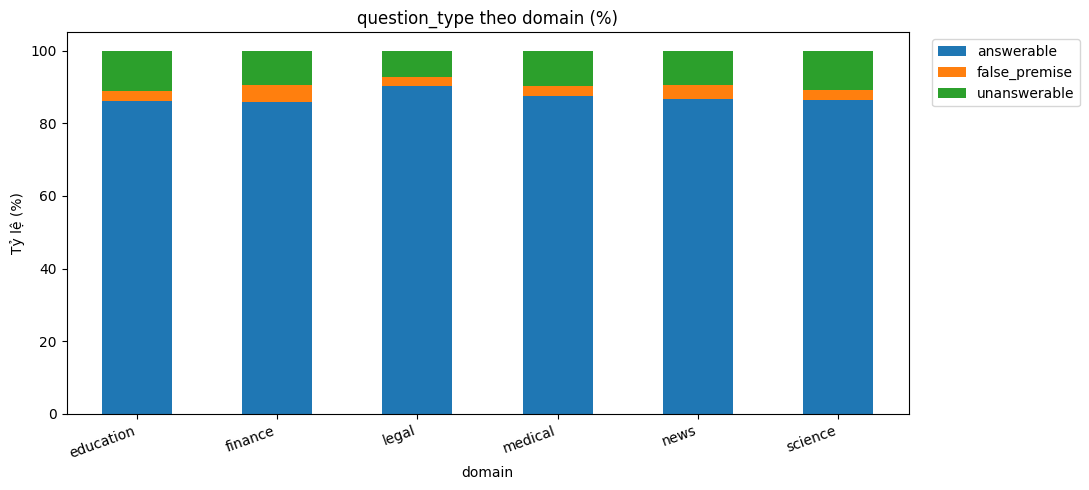

In [3]:
distributions = {}
for col in ["label", "domain", "question_type"]:
    distributions[col] = distribution(df[col], f"Phân phối {col}", f"distribution_{col}")
label_counts = df.label.value_counts()
note(f"**Nhận xét:** Nhãn nhiều nhất là **{label_counts.index[0]}** ({label_counts.iloc[0]:,} mẫu, {label_counts.iloc[0]/len(df):.2%}); nhãn ít nhất là **{label_counts.index[-1]}** ({label_counts.iloc[-1]:,} mẫu). Tỷ số lớn nhất/nhỏ nhất là **{label_counts.iloc[0]/label_counts.iloc[-1]:.2f}**. Tỷ lệ mẫu có hallucination là **{df.label.ne('no_hallucination').mean():.2%}**. Khi đánh giá mô hình, nên báo cáo kết quả từng nhãn và macro-F1 để quan sát ảnh hưởng của mất cân bằng.")

for group, target in [("domain", "label"), ("question_type", "label"), ("domain", "question_type")]:
    counts = pd.crosstab(df[group], df[target])
    pct = counts.div(counts.sum(axis=1), axis=0).mul(100)
    note(f"**{group} × {target}:** bảng số lượng và tỷ lệ % theo hàng.")
    display(counts); display(pct.round(2))
    save_table(counts, f"cross_{group}_{target}_count")
    save_table(pct, f"cross_{group}_{target}_percent")
    pct.plot.bar(stacked=True, figsize=(11, 5), title=f"{target} theo {group} (%)")
    plt.ylabel("Tỷ lệ (%)"); plt.xticks(rotation=20, ha="right")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    finish(f"cross_{group}_{target}")


## 3. Độ dài content, question và answer
Bảng mô tả gồm trung vị, các phân vị và cực trị; histogram cho thấy hình dạng phân phối, boxplot hỗ trợ so sánh theo nhãn. Điểm ngoài ngưỡng IQR chỉ là ứng viên cần kiểm tra, không tự động là dữ liệu lỗi.

In [4]:
lengths = pd.DataFrame(index=df.index)
for col in ["content", "question", "answer"]:
    text = df[col].fillna("").astype(str)
    lengths[f"{col}_chars"] = text.str.len()
    lengths[f"{col}_words"] = text.str.split().str.len()
length_summary = lengths.describe(percentiles=[.05, .25, .5, .75, .95, .99]).T
display(length_summary)
save_table(length_summary, "text_lengths")


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
content_chars,17082.0,404.720232,126.518890,161.0,209.0,298.0,405.0,507.0,591.0,700.00,996.0
content_words,17082.0,88.442220,27.267216,39.0,46.0,66.0,89.0,111.0,127.0,151.00,220.0
question_chars,17082.0,97.945732,30.924184,18.0,55.0,77.0,94.0,115.0,153.0,191.19,353.0
question_words,17082.0,21.818815,6.833892,4.0,12.0,17.0,21.0,26.0,34.0,42.19,76.0
answer_chars,17082.0,133.211334,75.677619,1.0,24.0,81.0,123.0,175.0,275.0,363.00,731.0
answer_words,17082.0,29.294345,16.627429,1.0,5.0,18.0,27.0,38.0,60.0,79.00,164.0


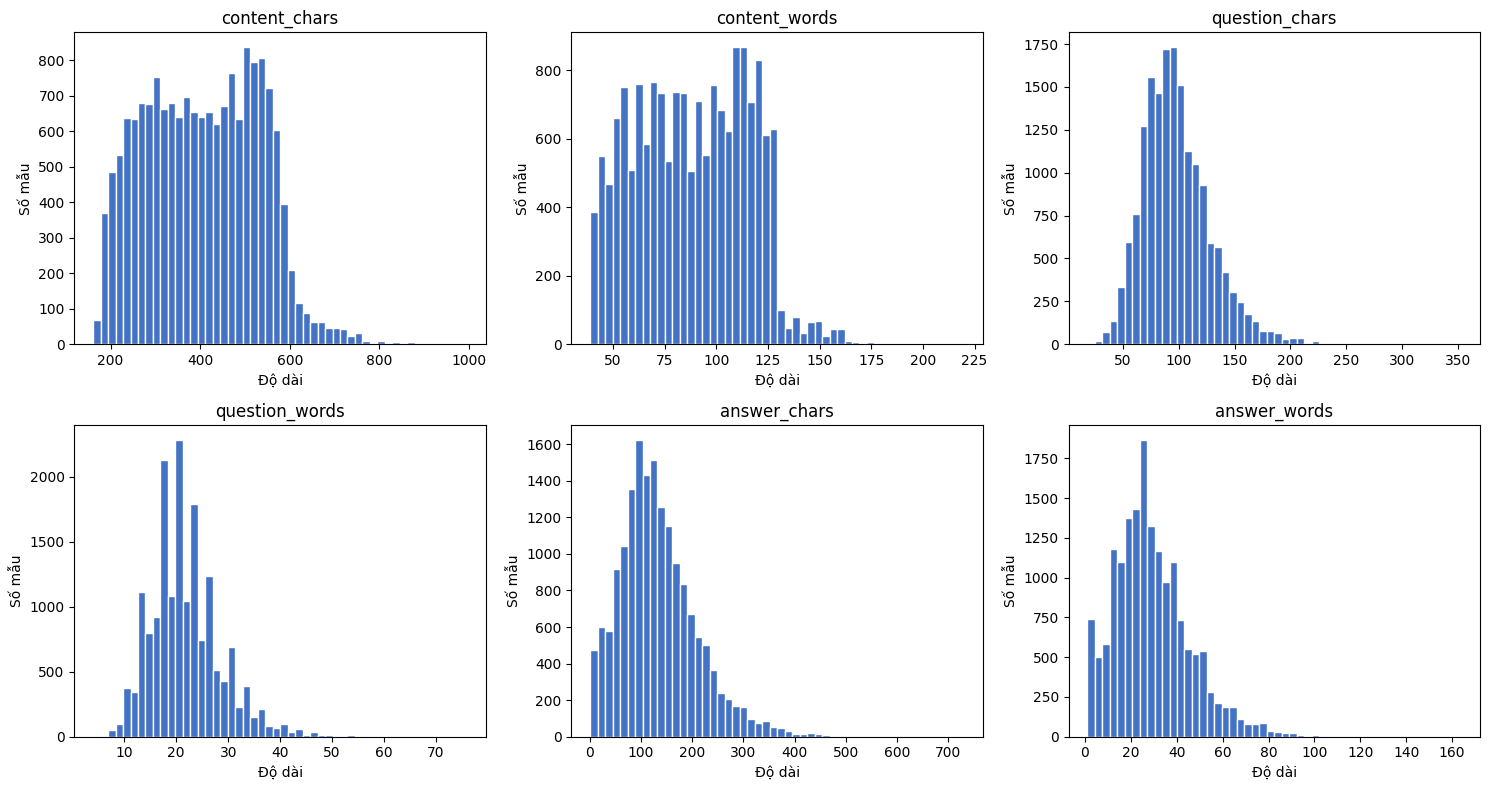

,count,mean,median,min,max
label,,,,,
extrinsic_hallucination,3210,84.39,83.0,39,179
intrinsic_hallucination,3665,86.61,86.0,39,220
mixed_hallucination,1343,92.00,94.0,40,183
no_hallucination,8864,90.13,91.0,39,220


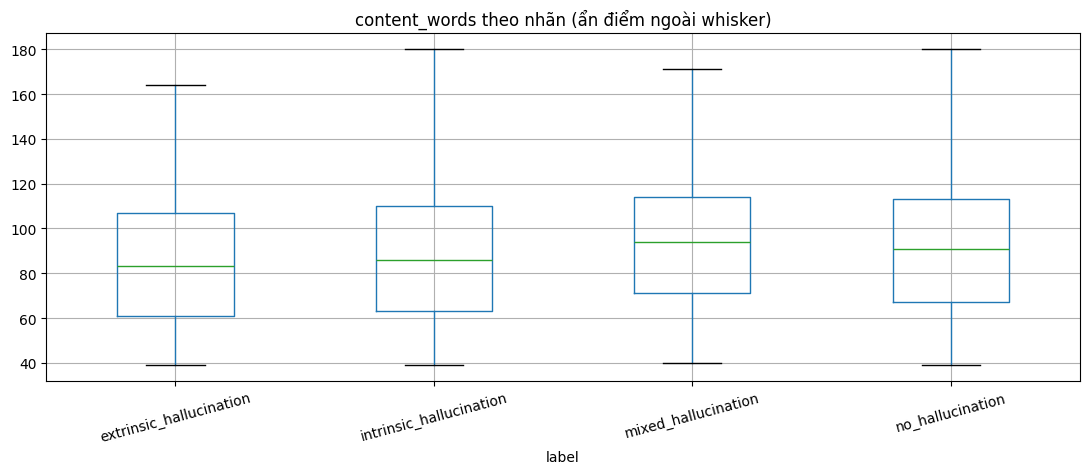

,count,mean,median,min,max
label,,,,,
extrinsic_hallucination,3210,21.44,21.0,5,65
intrinsic_hallucination,3665,21.12,20.0,4,67
mixed_hallucination,1343,23.76,23.0,7,55
no_hallucination,8864,21.95,21.0,5,76


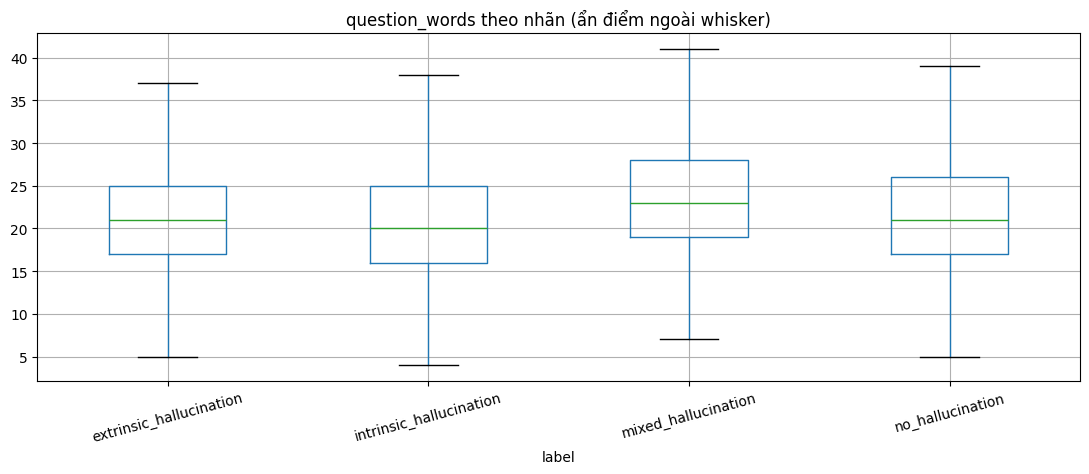

,count,mean,median,min,max
label,,,,,
extrinsic_hallucination,3210,33.30,31.0,1,129
intrinsic_hallucination,3665,26.44,25.0,2,82
mixed_hallucination,1343,52.53,50.0,17,164
no_hallucination,8864,25.50,23.0,1,112


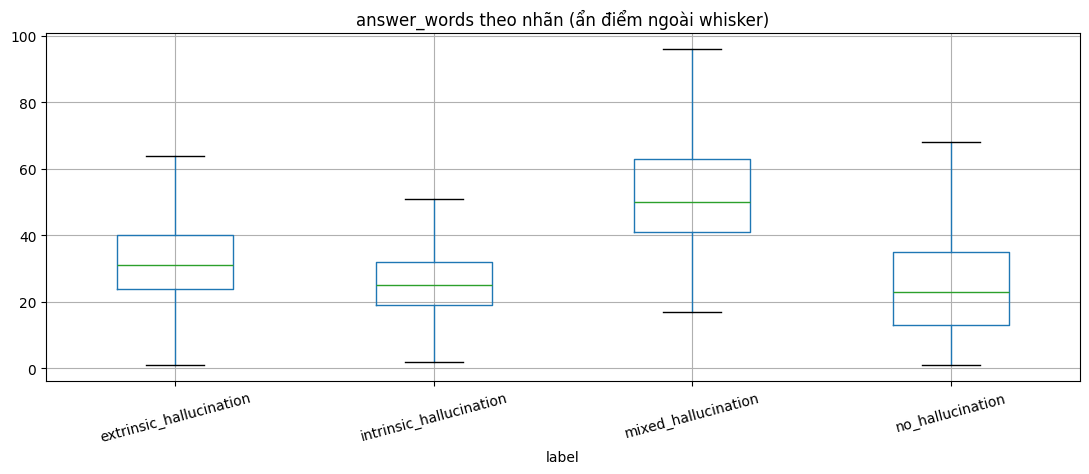

,qa_id,label,question,answer,answer_words
1663,legal_congbao_65409_chunk3__qa2,mixed_hallucination,Hệ thống quan trắc phóng xạ môi trường được th...,Hệ thống quan trắc phóng xạ môi trường được th...,164
10366,legal_congbao_70023_chunk11__qa1,extrinsic_hallucination,Ủy ban Mặt trận Tổ quốc Việt Nam các cấp cần t...,Ủy ban Mặt trận Tổ quốc Việt Nam các cấp cần s...,129
10828,education_dhsphue_90769_chunk22__qa1,mixed_hallucination,Điều kiện nào về huy chương và công nhận vận đ...,"Thí sinh đạt huy chương vàng, bạc hoặc đồng tạ...",118
15137,legal_congbao_39298_chunk86__qa1,mixed_hallucination,Trong trường hợp nào thì việc chấm dứt chương ...,Việc chấm dứt chương trình khuyến mại không yê...,118
703,legal_congbao_38603_chunk41__qa2,extrinsic_hallucination,Ai có thẩm quyền quyết định tặng danh hiệu Tập...,Danh hiệu Tập thể lao động xuất sắc do Bộ trưở...,117
10529,legal_congbao_78084_chunk43__qa3,mixed_hallucination,Ai là những người lãnh đạo cấp cao được quy đị...,Các đối tượng được bảo vệ tiếp cận và được bố ...,115
2749,legal_congbao_75461_chunk298__qa1,extrinsic_hallucination,Việc đánh giá phê bình sự phù hợp của các biện...,Cả hai đều là hoạt động đánh giá phê bình cách...,113
9317,education_utt_93857_chunk7__qa3,no_hallucination,Các hoạt động nào thuộc về lĩnh vực kinh tế và...,Các hoạt động thuộc lĩnh vực kinh tế và quản l...,112
10244,legal_congbao_42951_chunk7__qa1,no_hallucination,Hội đồng định giá thực hiện khảo sát giá bằng ...,Hội đồng định giá thực hiện khảo sát giá bằng ...,112
2806,legal_vbpl_37627_chunk89__qa1,mixed_hallucination,Hội đồng nhân dân cấp tỉnh xem xét văn bản nào...,"Theo đề nghị của Ủy ban nhân dân cấp tỉnh, Hội...",110


**Nhận xét:** Trung vị content/question/answer lần lượt là **89/21/27 đơn vị khoảng trắng**. Có **446 câu trả lời** vượt ngưỡng IQR trên (68.0). Cần kiểm tra nội dung trước khi quyết định lọc hoặc giới hạn độ dài.

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, lengths.columns):
    ax.hist(lengths[col], bins=50, color="#4472C4", edgecolor="white")
    ax.set_title(col); ax.set_ylabel("Số mẫu"); ax.set_xlabel("Độ dài")
finish("length_histograms")
for field in ["content_words", "question_words", "answer_words"]:
    grouped = pd.concat([df[["label", "domain"]], lengths[[field]]], axis=1)
    display(grouped.groupby("label")[field].agg(["count", "mean", "median", "min", "max"]).round(2))
    grouped.boxplot(column=field, by="label", figsize=(11, 5), showfliers=False)
    plt.suptitle(""); plt.title(f"{field} theo nhãn (ẩn điểm ngoài whisker)")
    plt.xticks(rotation=15); finish(f"boxplot_{field}_label")
q1, q3 = lengths.answer_words.quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
outliers = df.loc[lengths.answer_words.gt(upper), ["qa_id", "label", "question", "answer"]].copy()
outliers["answer_words"] = lengths.loc[outliers.index, "answer_words"]
display(outliers.nlargest(10, "answer_words"))
save_table(outliers, "long_answer_candidates")
note(f"**Nhận xét:** Trung vị content/question/answer lần lượt là **{lengths.content_words.median():.0f}/{lengths.question_words.median():.0f}/{lengths.answer_words.median():.0f} đơn vị khoảng trắng**. Có **{len(outliers):,} câu trả lời** vượt ngưỡng IQR trên ({upper:.1f}). Cần kiểm tra nội dung trước khi quyết định lọc hoặc giới hạn độ dài.")


## 4. Phân tích span hallucination
Tách từng span thành một dòng để phân tích label, diagnosis, repair_action và evidence. Phân phối span có mẫu số khác phân phối QA: một QA có thể đóng góp nhiều span. Tỷ lệ phủ dưới đây dùng số ký tự của span chia độ dài answer; nếu span trùng/chồng lấn, tổng có thể vượt 100%, nên đây là tỷ lệ độ dài annotation, không phải độ phủ hợp nhất.

,count,percent
0,8864,51.89
1,6703,39.24
2,1510,8.84
3,4,0.02
4,1,0.01


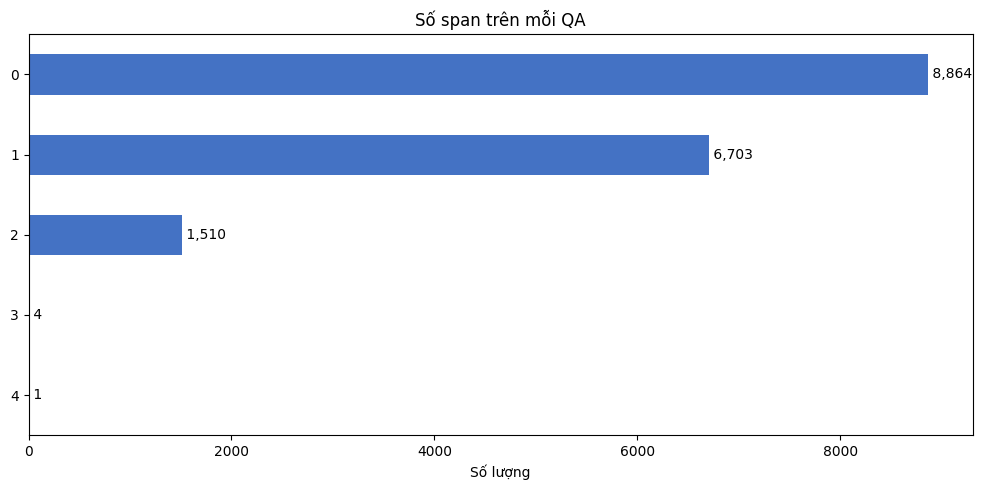

,count,percent
label,,
contradicted,5008,51.42
unsupported,4731,48.58


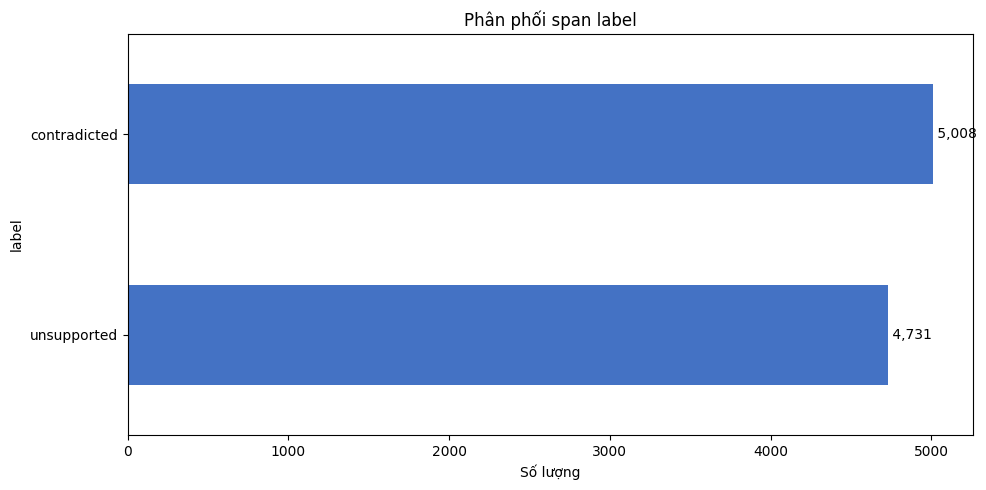

,count,percent
diagnosis,,
unsupported_addition,4632,47.56
entity_substitution,1565,16.07
circumstance_error,1126,11.56
predicate_error,978,10.04
numerical_distortion,921,9.46
sino_vietnamese_term_confusion,211,2.17
incorrect_reference,168,1.73
unsupported_reference,99,1.02
other,37,0.38


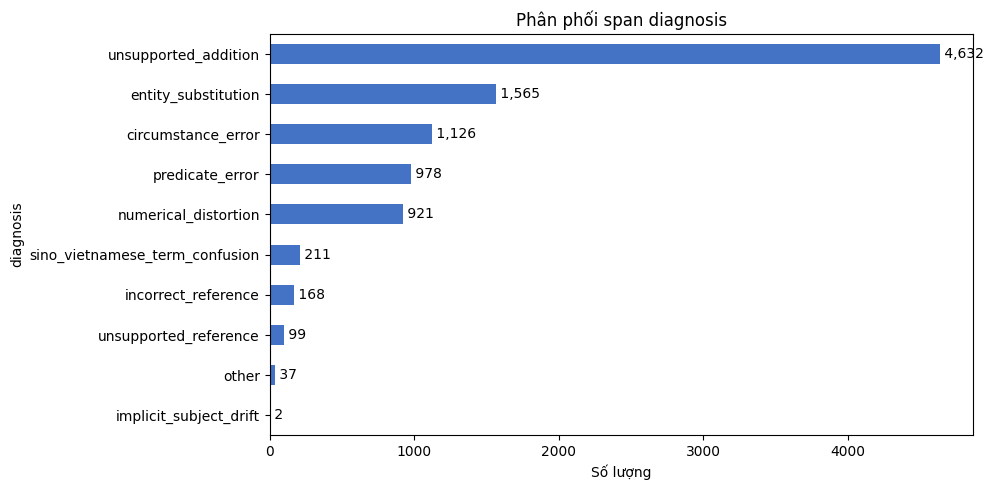

,count,percent
repair_action,,
replace_span,5057,51.93
delete_span,4473,45.93
delete_claim,199,2.04
rewrite_claim,10,0.10


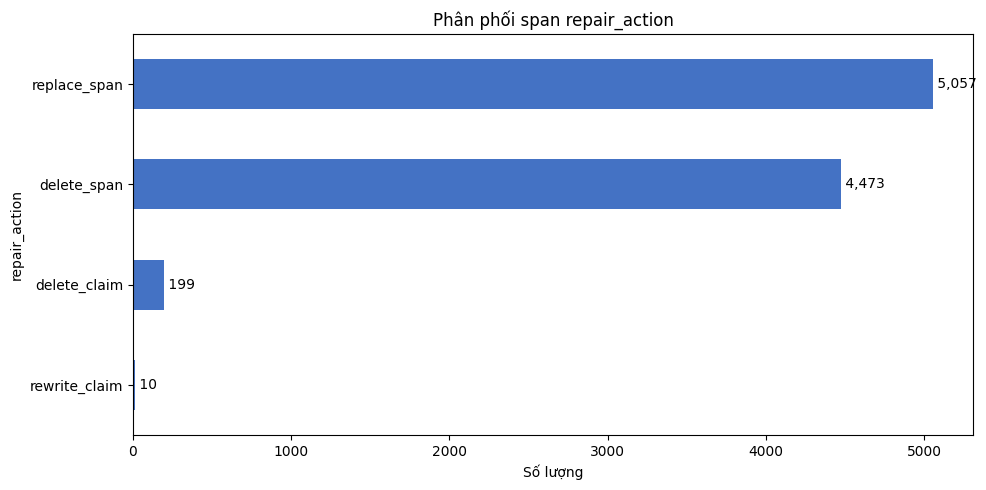

,count,mean,std,min,25%,50%,75%,max
span_chars,9739.0,28.190163,19.433214,1.0,14.0,25.0,38.0,253.0
span_words,9739.0,6.454461,4.361426,1.0,3.0,6.0,9.0,57.0


,count,with_evidence,with_evidence_percent
label,,,
contradicted,5008,5008,100.00
unsupported,4731,59,1.25


diagnosis,circumstance_error,entity_substitution,implicit_subject_drift,incorrect_reference,numerical_distortion,other,predicate_error,sino_vietnamese_term_confusion,unsupported_addition,unsupported_reference
label,,,,,,,,,,
contradicted,1126,1565,2,168,921,37,978,211,0,0
unsupported,0,0,0,0,0,0,0,0,4632,99


repair_action,delete_claim,delete_span,replace_span,rewrite_claim
diagnosis,,,,
circumstance_error,0,0,1125,1
entity_substitution,0,0,1563,2
implicit_subject_drift,0,0,2,0
incorrect_reference,0,0,168,0
numerical_distortion,0,0,920,1
other,0,0,37,0
predicate_error,0,0,972,6
sino_vietnamese_term_confusion,0,0,211,0
unsupported_addition,198,4376,58,0


label,contradicted,unsupported
domain,,
education,692,686
finance,887,763
legal,767,700
medical,737,833
news,1026,969
science,899,780


,annotation_length_ratio
count,8218.000000
mean,0.226240
std,0.150390
min,0.008021
25%,0.121212
50%,0.196970
75%,0.293673
max,1.000000


**Nhận xét:** Có **9,739 span** trong **8,218 QA**; trung bình **1.19 span/QA có annotation**. Có **0 QA** có tổng độ dài span lớn hơn answer, cần kiểm tra span trùng hoặc chồng lấn.

In [6]:
span_rows = []
invalid_span_rows = []
for idx, row in df.iterrows():
    annotations = row.span_label
    if not isinstance(annotations, list):
        invalid_span_rows.append(idx)
        continue
    for position, annotation in enumerate(annotations):
        if not isinstance(annotation, dict):
            invalid_span_rows.append(idx)
            continue
        span_rows.append({**annotation, "row_index": idx, "span_position": position,
            "qa_id": row.qa_id, "domain": row.domain, "qa_label": row.label,
            "question_type": row.question_type})
spans = pd.DataFrame(span_rows, columns=["span", "label", "evidence", "diagnosis", "repair_action",
    "row_index", "span_position", "qa_id", "domain", "qa_label", "question_type"])
span_counts = spans.groupby("row_index").size().reindex(df.index, fill_value=0)
distribution(span_counts, "Số span trên mỗi QA", "spans_per_qa")
for col in ["label", "diagnosis", "repair_action"]:
    distribution(spans[col], f"Phân phối span {col}", f"span_{col}")
spans["span_chars"] = spans.span.fillna("").astype(str).str.len()
spans["span_words"] = spans.span.fillna("").astype(str).str.split().str.len()
spans["evidence_present"] = spans.evidence.map(lambda v: isinstance(v, str) and bool(v.strip()))
display(spans[["span_chars", "span_words"]].describe().T)
evidence_stats = spans.groupby("label").evidence_present.agg(["count", "sum", "mean"])
evidence_stats["mean"] = (evidence_stats["mean"] * 100).round(2)
evidence_stats = evidence_stats.rename(columns={"sum": "with_evidence", "mean": "with_evidence_percent"})
display(evidence_stats); save_table(evidence_stats, "span_evidence")
for left, right in [("label", "diagnosis"), ("diagnosis", "repair_action"), ("domain", "label")]:
    table = pd.crosstab(spans[left], spans[right])
    display(table); save_table(table, f"span_cross_{left}_{right}")
coverage = spans.groupby("row_index").span_chars.sum().reindex(df.index, fill_value=0).div(lengths.answer_chars.replace(0, np.nan))
display(coverage[df.label.ne("no_hallucination")].describe().to_frame("annotation_length_ratio"))
note(f"**Nhận xét:** Có **{len(spans):,} span** trong **{int(span_counts.gt(0).sum()):,} QA**; trung bình **{span_counts[span_counts.gt(0)].mean():.2f} span/QA có annotation**. Có **{int(coverage.gt(1).sum()):,} QA** có tổng độ dài span lớn hơn answer, cần kiểm tra span trùng hoặc chồng lấn.")


## 5. Kiểm tra tính nhất quán annotation
Quy ước kiểm tra: no_hallucination không có span; intrinsic có contradicted; extrinsic có unsupported; mixed có cả hai. Đây là quy ước cần đối chiếu với hướng dẫn gán nhãn của dự án. Kiểm tra substring là so khớp chính xác, nên sai khác dấu câu/chuẩn hóa cũng có thể tạo cảnh báo. Các kiểm tra tự động không xác nhận được tính đúng đắn về ngữ nghĩa của evidence.

In [7]:
expected = {"no_hallucination": set(), "intrinsic_hallucination": {"contradicted"},
    "extrinsic_hallucination": {"unsupported"}, "mixed_hallucination": {"contradicted", "unsupported"}}
actual = spans.groupby("row_index")["label"].agg(lambda values: set(values.dropna()))
issues = []
for idx, row in df.iterrows():
    observed = actual.get(idx, set())
    if row.label not in expected or observed != expected.get(row.label):
        issues.append({"row_index": idx, "qa_id": row.qa_id, "issue": "qa_span_label_mismatch",
            "detail": f"QA={row.label}; span_labels={sorted(map(str, observed))}"})
for idx in sorted(set(invalid_span_rows)):
    issues.append({"row_index": idx, "qa_id": df.loc[idx, "qa_id"], "issue": "invalid_span_structure", "detail": "span_label phải là list các dict"})
for _, s in spans.iterrows():
    idx = int(s.row_index)
    for field in ["span", "label", "diagnosis", "repair_action"]:
        value = s[field]
        if not isinstance(value, str) or not value.strip():
            issues.append({"row_index": idx, "qa_id": s.qa_id, "issue": f"empty_or_invalid_{field}", "detail": str(s.span_position)})
    if isinstance(s.span, str) and s.span.strip() and s.span not in str(df.loc[idx, "answer"]):
        issues.append({"row_index": idx, "qa_id": s.qa_id, "issue": "span_not_in_answer", "detail": s.span})
    if s.label == "contradicted" and not s.evidence_present:
        issues.append({"row_index": idx, "qa_id": s.qa_id, "issue": "contradicted_missing_evidence", "detail": s.span})
    if s.evidence_present and s.evidence not in str(df.loc[idx, "content"]):
        issues.append({"row_index": idx, "qa_id": s.qa_id, "issue": "evidence_not_exact_substring", "detail": s.evidence})
issues_df = pd.DataFrame(issues, columns=["row_index", "qa_id", "issue", "detail"])
display(issues_df.issue.value_counts().to_frame("count"))
display(issues_df.head(20)); save_table(issues_df, "annotation_issues")
note(f"**Nhận xét:** Phát hiện **{len(issues_df):,} cảnh báo** trên **{issues_df.row_index.nunique():,} mẫu**. Một mẫu có thể có nhiều cảnh báo. Cần đọc trực tiếp các mẫu trước khi sửa; đặc biệt evidence không khớp substring có thể do evidence được diễn giải lại.")


,count
issue,


,row_index,qa_id,issue,detail


**Nhận xét:** Phát hiện **0 cảnh báo** trên **0 mẫu**. Một mẫu có thể có nhiều cảnh báo. Cần đọc trực tiếp các mẫu trước khi sửa; đặc biệt evidence không khớp substring có thể do evidence được diễn giải lại.

## 6. Mức độ tập trung theo tài liệu và nguy cơ rò rỉ khi chia tập
Thống kê số QA trên mỗi tài liệu/chunk và các câu hỏi lặp. Nhiều QA cùng tài liệu hoặc cùng content có thể chia sẻ thông tin; nên cân nhắc chia theo doc_id, đồng thời kiểm tra content trùng giữa tài liệu. Notebook không tự tạo train/test hoặc khẳng định đã có rò rỉ nếu chưa có tập chia.

,qa_per_doc_id
count,7822.000000
mean,2.183840
std,1.339726
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,15.000000


,qa_count
doc_id,
education_ueb_vnu_91248,15
education_ctu_17422,14
education_utt_59915,12
education_hvtc_41689,12
education_hcmus_98981,11
education_fpt_76830,11
legal_congbao_26160,11
education_hanoi_56038,11
education_hcmiu_07692,11


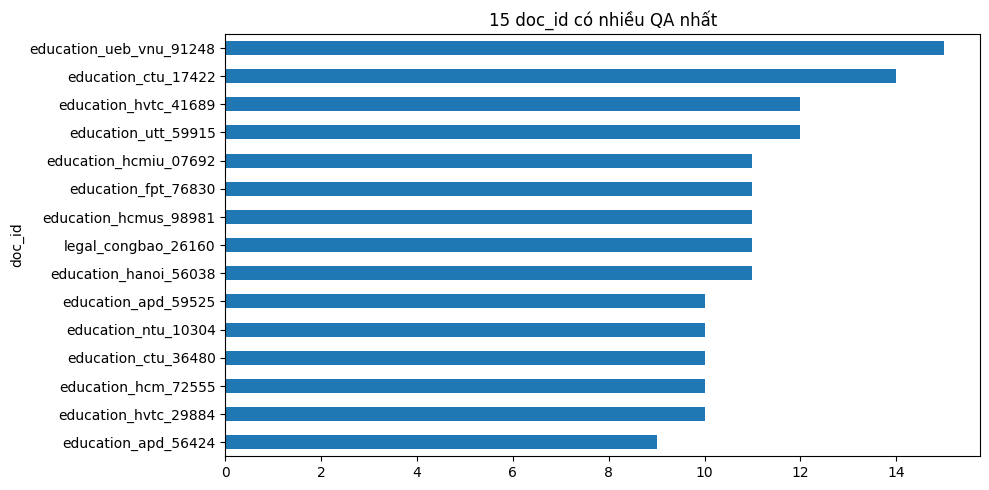

,qa_per_chunk_id
count,10346.000000
mean,1.651073
std,0.700367
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,7.000000


,qa_count
chunk_id,
legal_congbao_26160_chunk848,7
education_hueuni_18985_chunk3,6
finance_sbv_53148_chunk10,6
news_tuoitre_86483_chunk7,6
news_tuoitre_52540_chunk4,5
finance_sbv_72443_chunk7,4
news_vnexpress_07899_chunk2,4
news_thanhnien_36172_chunk1,4
news_tuoitre_70944_chunk5,4


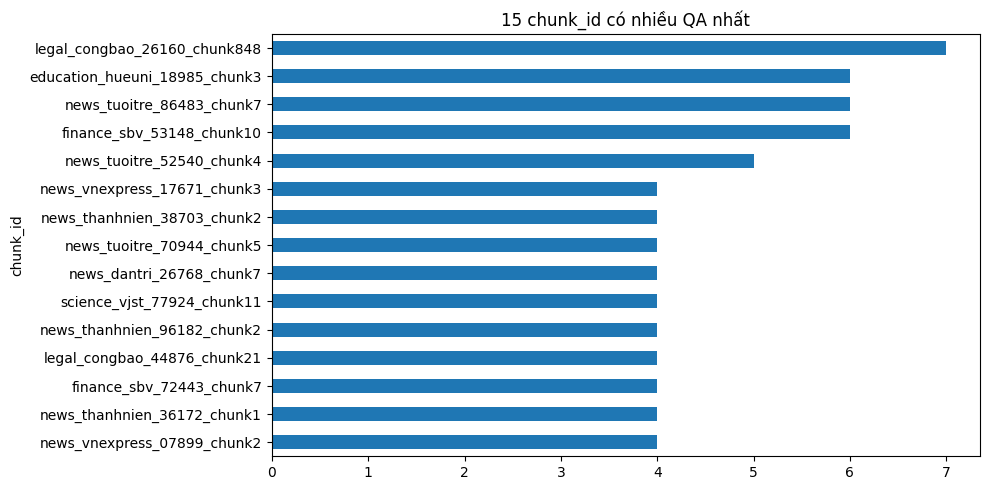

,qa_count,document_count,label_count
normalized_question,,,


**Nhận xét:** Có **0 lần lặp câu hỏi** sau lần đầu khi chuẩn hóa chữ thường/khoảng trắng; **0 nhóm content** xuất hiện ở nhiều doc_id. Có **0 nhóm content–question** chứa nhiều nhãn; điều này có thể phù hợp nếu answer là các biến thể hallucination. Chia ngẫu nhiên theo dòng cần kiểm tra các nhóm này trước khi đánh giá mô hình.

In [8]:
for key in ["doc_id", "chunk_id"]:
    group_sizes = df.groupby(key).size().sort_values(ascending=False)
    display(group_sizes.describe().to_frame(f"qa_per_{key}"))
    display(group_sizes.head(15).to_frame("qa_count"))
    save_table(group_sizes.to_frame("qa_count"), f"qa_per_{key}")
    group_sizes.head(15).sort_values().plot.barh(title=f"15 {key} có nhiều QA nhất")
    finish(f"top_{key}")
normalized_question = df.question.fillna("").astype(str).str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
normalized_content = df.content.fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
content_groups = df.assign(normalized_content=normalized_content).groupby("normalized_content").agg(
    qa_count=("qa_id", "size"), document_count=("doc_id", "nunique"))
cross_document_content = content_groups[content_groups.document_count.gt(1)]
save_table(cross_document_content, "shared_content_across_documents")
question_groups = df.assign(normalized_question=normalized_question).groupby("normalized_question").agg(
    qa_count=("qa_id", "size"), document_count=("doc_id", "nunique"), label_count=("label", "nunique"))
display(question_groups[question_groups.qa_count.gt(1)].sort_values("qa_count", ascending=False).head(15))
save_table(question_groups[question_groups.qa_count.gt(1)], "repeated_questions")
label_per_context = df.groupby(["content", "question"]).label.nunique()
note(f"**Nhận xét:** Có **{int(normalized_question.duplicated().sum()):,} lần lặp câu hỏi** sau lần đầu khi chuẩn hóa chữ thường/khoảng trắng; **{len(cross_document_content):,} nhóm content** xuất hiện ở nhiều doc_id. Có **{int(label_per_context.gt(1).sum()):,} nhóm content–question** chứa nhiều nhãn; điều này có thể phù hợp nếu answer là các biến thể hallucination. Chia ngẫu nhiên theo dòng cần kiểm tra các nhóm này trước khi đánh giá mô hình.")


## 7. Tổng kết và xuất kết quả
Các bảng CSV (UTF-8 BOM) và biểu đồ PNG được lưu vào `output/analysis_final/`, thuận tiện dùng trong báo cáo. Dataset này không cung cấp lịch sử loại mẫu hay cột train/validation/test: để đánh giá hiệu quả làm sạch và rò rỉ giữa các tập, cần bổ sung dữ liệu trước xử lý và tập đã chia.

Phân phối và kiểm tra cấu trúc không thay thế đánh giá chất lượng ngữ nghĩa. Nên đọc mẫu từ mỗi tổ hợp domain–label–question_type và ưu tiên các mẫu có cảnh báo.

In [9]:
sample_review = (df.groupby(["domain", "label", "question_type"], group_keys=False)
    .sample(frac=1, random_state=42)
    .groupby(["domain", "label", "question_type"], group_keys=False).head(2))
save_table(sample_review, "stratified_manual_review_samples")
summary = f"""# Tổng kết dataset cuối
- Số QA: {len(df):,}; tài liệu: {df.doc_id.nunique():,}; chunk: {df.chunk_id.nunique():,}.
- Tỷ lệ mẫu có hallucination: {df.label.ne('no_hallucination').mean():.2%}.
- Nhãn lớn nhất/nhỏ nhất: {label_counts.index[0]} / {label_counts.index[-1]}; tỷ số {label_counts.iloc[0]/label_counts.iloc[-1]:.2f}.
- Tổng span: {len(spans):,}; QA có span: {int(span_counts.gt(0).sum()):,}.
- Cảnh báo annotation: {len(issues_df):,} trên {issues_df.row_index.nunique():,} QA; cần rà soát thủ công.
- Dòng trùng hoàn toàn sau lần đầu: {int(duplicate_stats.loc['extra_exact_rows', 'count']):,}.
- Nhóm content chia sẻ giữa nhiều tài liệu: {len(cross_document_content):,}.
- Trung vị độ dài content/question/answer: {lengths.content_words.median():.0f}/{lengths.question_words.median():.0f}/{lengths.answer_words.median():.0f} đơn vị tách khoảng trắng.

Các cảnh báo không tự động có nghĩa là dữ liệu sai. Chưa đánh giá chất lượng evidence về ngữ nghĩa, hiệu quả làm sạch trước/sau hoặc rò rỉ giữa các tập đã chia.
"""
note(summary)
(REPORT_DIR / "summary.md").write_text(summary, encoding="utf-8")
print(f"Đã xuất bảng, biểu đồ và ghi chú tại: {REPORT_DIR.resolve()}")


# Tổng kết dataset cuối
- Số QA: 17,082; tài liệu: 7,822; chunk: 10,346.
- Tỷ lệ mẫu có hallucination: 48.11%.
- Nhãn lớn nhất/nhỏ nhất: no_hallucination / mixed_hallucination; tỷ số 6.60.
- Tổng span: 9,739; QA có span: 8,218.
- Cảnh báo annotation: 0 trên 0 QA; cần rà soát thủ công.
- Dòng trùng hoàn toàn sau lần đầu: 0.
- Nhóm content chia sẻ giữa nhiều tài liệu: 0.
- Trung vị độ dài content/question/answer: 89/21/27 đơn vị tách khoảng trắng.

Các cảnh báo không tự động có nghĩa là dữ liệu sai. Chưa đánh giá chất lượng evidence về ngữ nghĩa, hiệu quả làm sạch trước/sau hoặc rò rỉ giữa các tập đã chia.


Đã xuất bảng, biểu đồ và ghi chú tại: /home/trang/study/khoaluan/KLTN/src/dataset_curation/output/analysis_final
